<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Dynamic_delta_hedging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DYNAMIC DELTA HEDGING & HEDGING ERROR ANALYSIS

Initial Stock Price : 100.00
Strike Price        : 100.00
Risk-Free Rate      : 5.00%
Volatility          : 20.00%
Initial Call Premium: 10.4506
Initial Call Delta  : 0.6368

Simulated price paths: (5000, 253)

STRATEGY PERFORMANCE COMPARISON
                Mean P&L  P&L Std Dev  Mean Absolute P&L  Probability of Loss (%)  95% VaR (Loss)  95% Expected Shortfall  Average Turnover
Daily            -0.2893       0.4490             0.4030                    76.80          1.0813                  1.3990          550.5312
Weekly           -0.1430       0.9676             0.7389                    56.58          1.7613                  2.3793          282.2150
Monthly          -0.0645       1.9544             1.4944                    50.96          3.2714                  4.5981          163.8207
Every 3 Months    0.0000       3.2233             2.4970                    48.26          5.4687                  7.6861          112.5098
Unhedged 

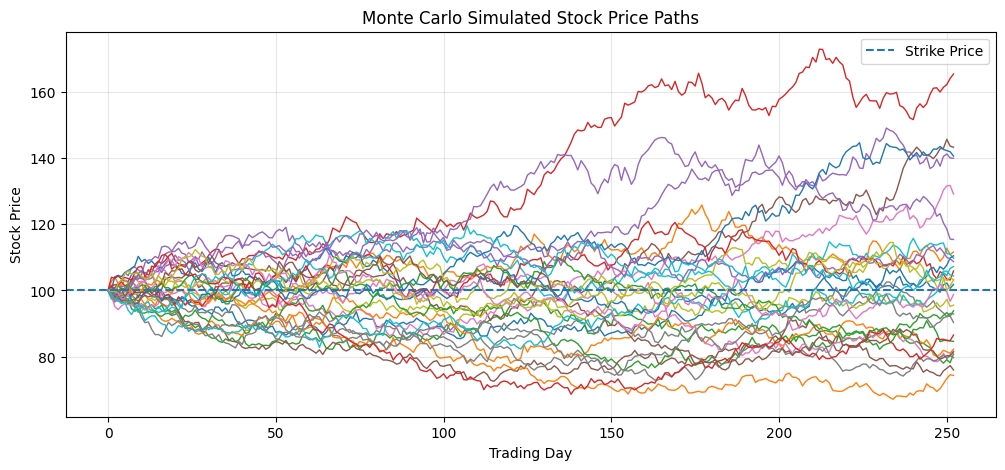

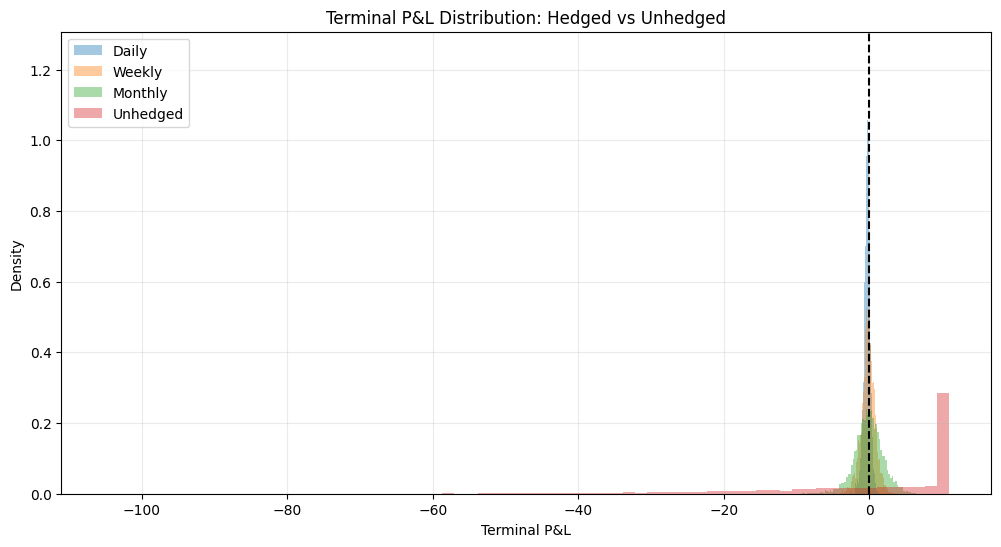


REBALANCING FREQUENCY ANALYSIS
 Rebalance Interval (Days)  Mean P&L  P&L Std Dev  Mean Absolute P&L  Average Turnover
                         1   -0.2893       0.4490             0.4030          550.5312
                         2   -0.2066       0.6224             0.4894          406.7592
                         5   -0.1430       0.9676             0.7389          282.2150
                        10   -0.1019       1.3355             1.0145          220.1481
                        21   -0.0645       1.9544             1.4944          163.8207
                        42   -0.0447       2.7235             2.0934          129.1921
                        63    0.0000       3.2233             2.4970          112.5098
                       126   -0.0240       4.4038             3.4781           87.9606
                       252    0.0574       5.9901             4.8010           63.6831


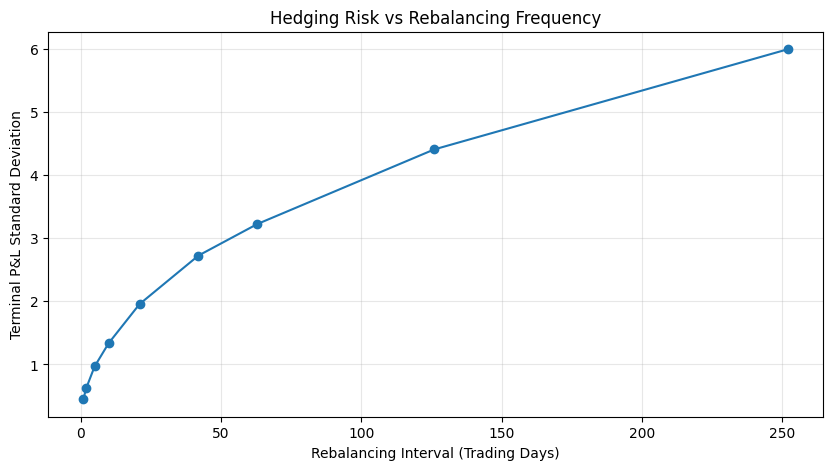

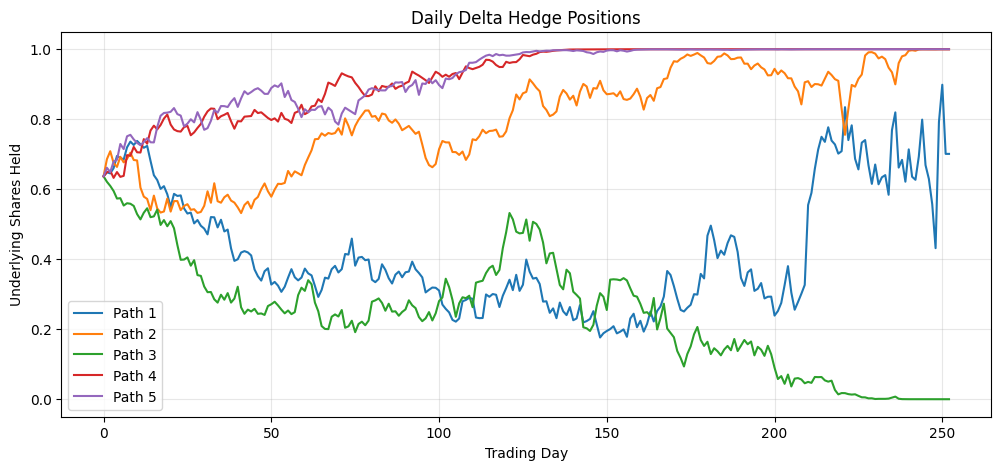


FINAL RESEARCH SUMMARY

Daily Strategy
----------------------------------------
Mean P&L              : -0.2893
P&L Standard Deviation: 0.4490
Probability of Loss   : 76.80%

Weekly Strategy
----------------------------------------
Mean P&L              : -0.1430
P&L Standard Deviation: 0.9676
Probability of Loss   : 56.58%

Monthly Strategy
----------------------------------------
Mean P&L              : -0.0645
P&L Standard Deviation: 1.9544
Probability of Loss   : 50.96%

Every 3 Months Strategy
----------------------------------------
Mean P&L              : 0.0000
P&L Standard Deviation: 3.2233
Probability of Loss   : 48.26%

Unhedged Strategy
----------------------------------------
Mean P&L              : 0.4111
P&L Standard Deviation: 15.0198
Probability of Loss   : 34.56%

Key observations to investigate:
1. How much does delta hedging reduce P&L variability?
2. How does rebalancing frequency affect hedging error?
3. How do transaction costs change the results?
4. Does lower 

In [ ]:
# ================================================================
# DYNAMIC DELTA HEDGING & HEDGING ERROR ANALYSIS
# Model: Black-Scholes | Monte Carlo | Transaction Costs
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(42)

# -------------------- 1. PARAMETERS ------------------------------

S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

N_PATHS = 5000
N_STEPS = 252
DT = T / N_STEPS

TRANSACTION_COST = 0.0005  # 5 basis points

print("=" * 70)
print("DYNAMIC DELTA HEDGING & HEDGING ERROR ANALYSIS")
print("=" * 70)

# -------------------- 2. BLACK-SCHOLES MODEL ---------------------

def bs_call_price(S, K, T, r, sigma):
    S = np.asarray(S, dtype=float)

    if T <= 0:
        return np.maximum(S - K, 0.0)

    d1 = (
        np.log(S / K) + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def bs_call_delta(S, K, T, r, sigma):
    S = np.asarray(S, dtype=float)

    if T <= 0:
        return (S > K).astype(float)

    d1 = (
        np.log(S / K) + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    return norm.cdf(d1)


initial_premium = float(bs_call_price(S0, K, T, r, sigma))
initial_delta = float(bs_call_delta(S0, K, T, r, sigma))

print(f"\nInitial Stock Price : {S0:.2f}")
print(f"Strike Price        : {K:.2f}")
print(f"Risk-Free Rate      : {r:.2%}")
print(f"Volatility          : {sigma:.2%}")
print(f"Initial Call Premium: {initial_premium:.4f}")
print(f"Initial Call Delta  : {initial_delta:.4f}")

# -------------------- 3. MONTE CARLO SIMULATION ------------------

Z = np.random.standard_normal((N_PATHS, N_STEPS))

S = np.zeros((N_PATHS, N_STEPS + 1))
S[:, 0] = S0

for t in range(N_STEPS):
    S[:, t + 1] = S[:, t] * np.exp(
        (r - 0.5 * sigma**2) * DT
        + sigma * np.sqrt(DT) * Z[:, t]
    )

print("\nSimulated price paths:", S.shape)

# -------------------- 4. DYNAMIC DELTA HEDGING -------------------

def simulate_delta_hedge(
    S,
    K,
    T,
    r,
    sigma,
    premium,
    rebalance_every,
    transaction_cost=0.0005
):
    n_paths, n_columns = S.shape
    n_steps = n_columns - 1
    dt = T / n_steps

    # Short one call; hedge with positive delta shares
    stock_position = bs_call_delta(S[:, 0], K, T, r, sigma)

    # Cash received from option premium, less stock hedge cost
    cash = premium - stock_position * S[:, 0]

    # Initial stock purchase incurs transaction costs
    initial_turnover = np.abs(stock_position * S[:, 0])
    cash -= transaction_cost * initial_turnover

    total_turnover = initial_turnover.copy()

    hedge_history = np.zeros_like(S)
    hedge_history[:, 0] = stock_position

    for t in range(1, n_steps + 1):

        # Cash earns the risk-free rate
        cash *= np.exp(r * dt)

        tau = T - t * dt

        # Rebalance before expiry according to schedule
        if t < n_steps and t % rebalance_every == 0:

            new_delta = bs_call_delta(
                S[:, t], K, tau, r, sigma
            )

            trade = new_delta - stock_position
            traded_notional = np.abs(trade * S[:, t])

            # Pay for stock purchases / receive proceeds from sales
            cash -= trade * S[:, t]

            # Pay transaction costs
            cash -= transaction_cost * traded_notional

            total_turnover += traded_notional
            stock_position = new_delta

        hedge_history[:, t] = stock_position

    # Liquidate remaining shares and settle the short call
    terminal_stock_value = stock_position * S[:, -1]
    terminal_payoff = np.maximum(S[:, -1] - K, 0.0)

    final_pnl = cash + terminal_stock_value - terminal_payoff

    return {
        "pnl": final_pnl,
        "turnover": total_turnover,
        "hedge_history": hedge_history
    }


# -------------------- 5. COMPARE STRATEGIES ----------------------

strategies = {
    "Daily": 1,
    "Weekly": 5,
    "Monthly": 21,
    "Every 3 Months": 63
}

results = {}

for name, frequency in strategies.items():
    results[name] = simulate_delta_hedge(
        S=S,
        K=K,
        T=T,
        r=r,
        sigma=sigma,
        premium=initial_premium,
        rebalance_every=frequency,
        transaction_cost=TRANSACTION_COST
    )

# Unhedged short-call benchmark
unhedged_pnl = (
    initial_premium * np.exp(r * T)
    - np.maximum(S[:, -1] - K, 0.0)
)

results["Unhedged"] = {
    "pnl": unhedged_pnl,
    "turnover": np.zeros(N_PATHS)
}

# -------------------- 6. PERFORMANCE METRICS ---------------------

def calculate_metrics(pnl, turnover=None):
    pnl = np.asarray(pnl)
    losses = -pnl

    var_95 = np.quantile(losses, 0.95)
    tail_losses = losses[losses >= var_95]

    output = {
        "Mean P&L": pnl.mean(),
        "P&L Std Dev": pnl.std(ddof=1),
        "Mean Absolute P&L": np.abs(pnl).mean(),
        "Probability of Loss (%)": (pnl < 0).mean() * 100,
        "95% VaR (Loss)": var_95,
        "95% Expected Shortfall": tail_losses.mean()
    }

    if turnover is not None:
        output["Average Turnover"] = np.mean(turnover)

    return output


metrics = {}

for name, result in results.items():
    metrics[name] = calculate_metrics(
        result["pnl"],
        result.get("turnover")
    )

metrics_df = pd.DataFrame(metrics).T

print("\n" + "=" * 70)
print("STRATEGY PERFORMANCE COMPARISON")
print("=" * 70)
print(metrics_df.round(4).to_string())

# -------------------- 7. SIMULATED STOCK PRICE PATHS --------------

plt.figure(figsize=(12, 5))

for i in range(30):
    plt.plot(S[i], linewidth=1)

plt.axhline(K, linestyle="--", label="Strike Price")
plt.title("Monte Carlo Simulated Stock Price Paths")
plt.xlabel("Trading Day")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# -------------------- 8. TERMINAL P&L DISTRIBUTIONS ---------------

plt.figure(figsize=(12, 6))

for name in ["Daily", "Weekly", "Monthly", "Unhedged"]:
    plt.hist(
        results[name]["pnl"],
        bins=70,
        alpha=0.40,
        density=True,
        label=name
    )

plt.axvline(0, color="black", linestyle="--")
plt.title("Terminal P&L Distribution: Hedged vs Unhedged")
plt.xlabel("Terminal P&L")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# -------------------- 9. REBALANCING FREQUENCY ANALYSIS ----------

frequency_results = []

for frequency in [1, 2, 5, 10, 21, 42, 63, 126, 252]:

    result = simulate_delta_hedge(
        S=S,
        K=K,
        T=T,
        r=r,
        sigma=sigma,
        premium=initial_premium,
        rebalance_every=frequency,
        transaction_cost=TRANSACTION_COST
    )

    pnl = result["pnl"]

    frequency_results.append({
        "Rebalance Interval (Days)": frequency,
        "Mean P&L": pnl.mean(),
        "P&L Std Dev": pnl.std(ddof=1),
        "Mean Absolute P&L": np.abs(pnl).mean(),
        "Average Turnover": result["turnover"].mean()
    })

frequency_df = pd.DataFrame(frequency_results)

print("\n" + "=" * 70)
print("REBALANCING FREQUENCY ANALYSIS")
print("=" * 70)
print(frequency_df.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))

plt.plot(
    frequency_df["Rebalance Interval (Days)"],
    frequency_df["P&L Std Dev"],
    marker="o"
)

plt.title("Hedging Risk vs Rebalancing Frequency")
plt.xlabel("Rebalancing Interval (Trading Days)")
plt.ylabel("Terminal P&L Standard Deviation")
plt.grid(alpha=0.3)
plt.show()

# -------------------- 10. HEDGE POSITION VISUALIZATION -----------

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.plot(
        results["Daily"]["hedge_history"][i],
        label=f"Path {i + 1}"
    )

plt.title("Daily Delta Hedge Positions")
plt.xlabel("Trading Day")
plt.ylabel("Underlying Shares Held")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# -------------------- 11. FINAL RESEARCH SUMMARY -----------------

print("\n" + "=" * 70)
print("FINAL RESEARCH SUMMARY")
print("=" * 70)

for name in ["Daily", "Weekly", "Monthly", "Every 3 Months", "Unhedged"]:
    pnl = results[name]["pnl"]

    print(f"\n{name} Strategy")
    print("-" * 40)
    print(f"Mean P&L              : {pnl.mean():.4f}")
    print(f"P&L Standard Deviation: {pnl.std(ddof=1):.4f}")
    print(f"Probability of Loss   : {(pnl < 0).mean():.2%}")

print("\nKey observations to investigate:")
print("1. How much does delta hedging reduce P&L variability?")
print("2. How does rebalancing frequency affect hedging error?")
print("3. How do transaction costs change the results?")
print("4. Does lower hedging risk justify higher trading turnover?")
print("5. How does the unhedged short-call tail risk compare?")

print("\nResearch caveat:")
print("This is a simulated Black-Scholes experiment, not a live-market backtest.")
print("The model assumes constant volatility and frictionless underlying prices.")
print("Transaction costs are included, but other real-world frictions are omitted.")